In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import joblib
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
dts_test = tf.data.Dataset.load("../data/dts_test")
dts_train = tf.data.Dataset.load("../data/dts_train")
dts_val = tf.data.Dataset.load("../data/dts_val")

BATCH_SIZE = 32
IMG_SIZE = (224 , 224)
IMG_SHAPE = (224 , 224 , 3)

# normalization
def preprocess_image(img, label):
    img = tf.keras.applications.mobilenet_v2.preprocess_input(img)
    return img, label

dts_train = dts_train.map(preprocess_image)
dts_val = dts_val.map(preprocess_image)
dts_test = dts_test.map(preprocess_image)

<h1>FEATURE EXTRACTION</h1>

In [13]:
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE , include_top=False , weights="imagenet")
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomRotation(0.1)
])

In [14]:
kernel_regularizer=tf.keras.regularizers.l2(0.0001)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE , include_top=False , weights="imagenet")
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)  # Data Augmentation
x = base_model(inputs , training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128 , activation='relu' , kernel_regularizer=kernel_regularizer)(x)
x = tf.keras.layers.Dropout(0.5)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax" ,  kernel_regularizer=kernel_regularizer)(x)
model = tf.keras.Model(inputs ,outputs )
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001) , loss="sparse_categorical_crossentropy" , metrics=["accuracy"])

In [15]:
early_s = tf.keras.callbacks.EarlyStopping(monitor='val_loss' , patience=7 , restore_best_weights=True )
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss' , patience=2 , factor=0.2 , min_lr=1e-6 , verbose=1 )
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath='../models/best_classification_model.keras' ,monitor="val_loss" , save_best_only=True , mode="min" , verbose=1 )
history = model.fit(dts_train , validation_data=dts_val , epochs=30 , callbacks=[early_s , reduce_lr , model_checkpoint])

joblib.dump(history.history , "../models/best_classification_model_history.pkl")


Epoch 1/30


c:\Users\ouich\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.8013 - loss: 0.5257
Epoch 1: val_loss improved from None to 0.56533, saving model to ../models/best_classification_model.keras

Epoch 1: finished saving model to ../models/best_classification_model.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 31s 220ms/step - accuracy: 0.8013 - loss: 0.5257 - val_accuracy: 0.7891 - val_loss: 0.5653 - learning_rate: 0.0010
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8815 - loss: 0.3370
Epoch 2: val_loss improved from 0.56533 to 0.41916, saving model to ../models/best_classification_model.keras

Epoch 2: finished saving model to ../models/best_classification_model.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 23s 190ms/step - accuracy: 0.8815 - loss: 0.3370 - val_accuracy: 0.8418 - val_loss: 0.4192 - learning_rate: 0.0010
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9045 - loss: 0.2706
Epoch 3: val_loss improved from 0.41916 to 0.37230, saving model to ../models/best_class

['../models/best_classification_model_history.pkl']

<h1>EVALUATION </h1>

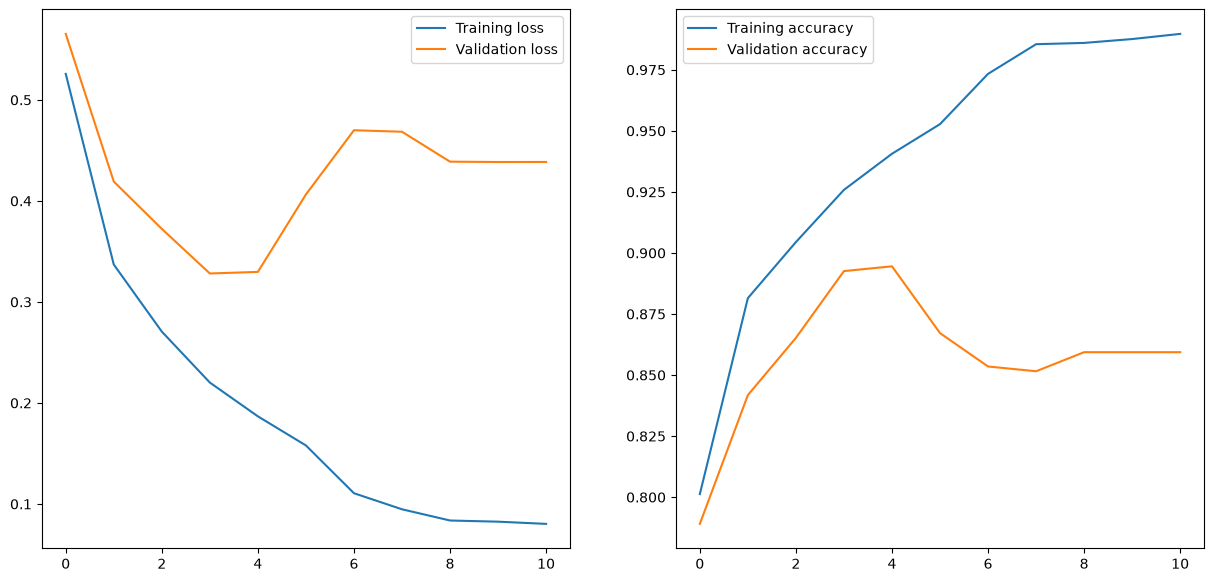

In [17]:
# history.history
history = joblib.load('../models/best_classification_model_history.pkl')
fig ,axes =  plt.subplots(1 , 2 , figsize=(15 , 7))
axes[0].plot(history['loss'] , label="Training loss")
axes[0].plot(history['val_loss'] , label="Validation loss")
axes[0].legend()

axes[1].plot(history['accuracy'] , label="Training accuracy")
axes[1].plot(history['val_accuracy'] , label="Validation accuracy")
axes[1].legend()
plt.show()

In [18]:
best_model = tf.keras.models.load_model("../models/best_classification_model.keras")
test_loss, test_accuracy = best_model.evaluate(dts_test)
y_pred_purcentages = best_model.predict(dts_test)
y_pred = np.argmax(y_pred_purcentages ,axis=1)
y_true = np.concatenate([labels.numpy() for _ , labels in dts_test])
cm = confusion_matrix(y_pred=y_pred , y_true=y_true)

30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.8755 - loss: 0.3453
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 174ms/step


In [19]:
report = classification_report(y_true,y_pred,target_names=["Glioma","Meningioma","No Tumor","Pituitary"])
wrong_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions : ", len(wrong_indices))
print("Total test images : ", len(y_true))
print("Test loss : ", test_loss)
print("Test accuracy : ", test_accuracy)
print("confusion_matrix : \n" , cm)
print("classification_report : \n" , report)

Incorrect predictions :  118
Total test images :  948
Test loss :  0.3453483283519745
Test accuracy :  0.8755274415016174
confusion_matrix : 
 [[186  40   0   5]
 [ 28 234   9  19]
 [  6   5 129   2]
 [  1   3   0 281]]
classification_report : 
               precision    recall  f1-score   support

      Glioma       0.84      0.81      0.82       231
  Meningioma       0.83      0.81      0.82       290
    No Tumor       0.93      0.91      0.92       142
   Pituitary       0.92      0.99      0.95       285

    accuracy                           0.88       948
   macro avg       0.88      0.88      0.88       948
weighted avg       0.87      0.88      0.87       948



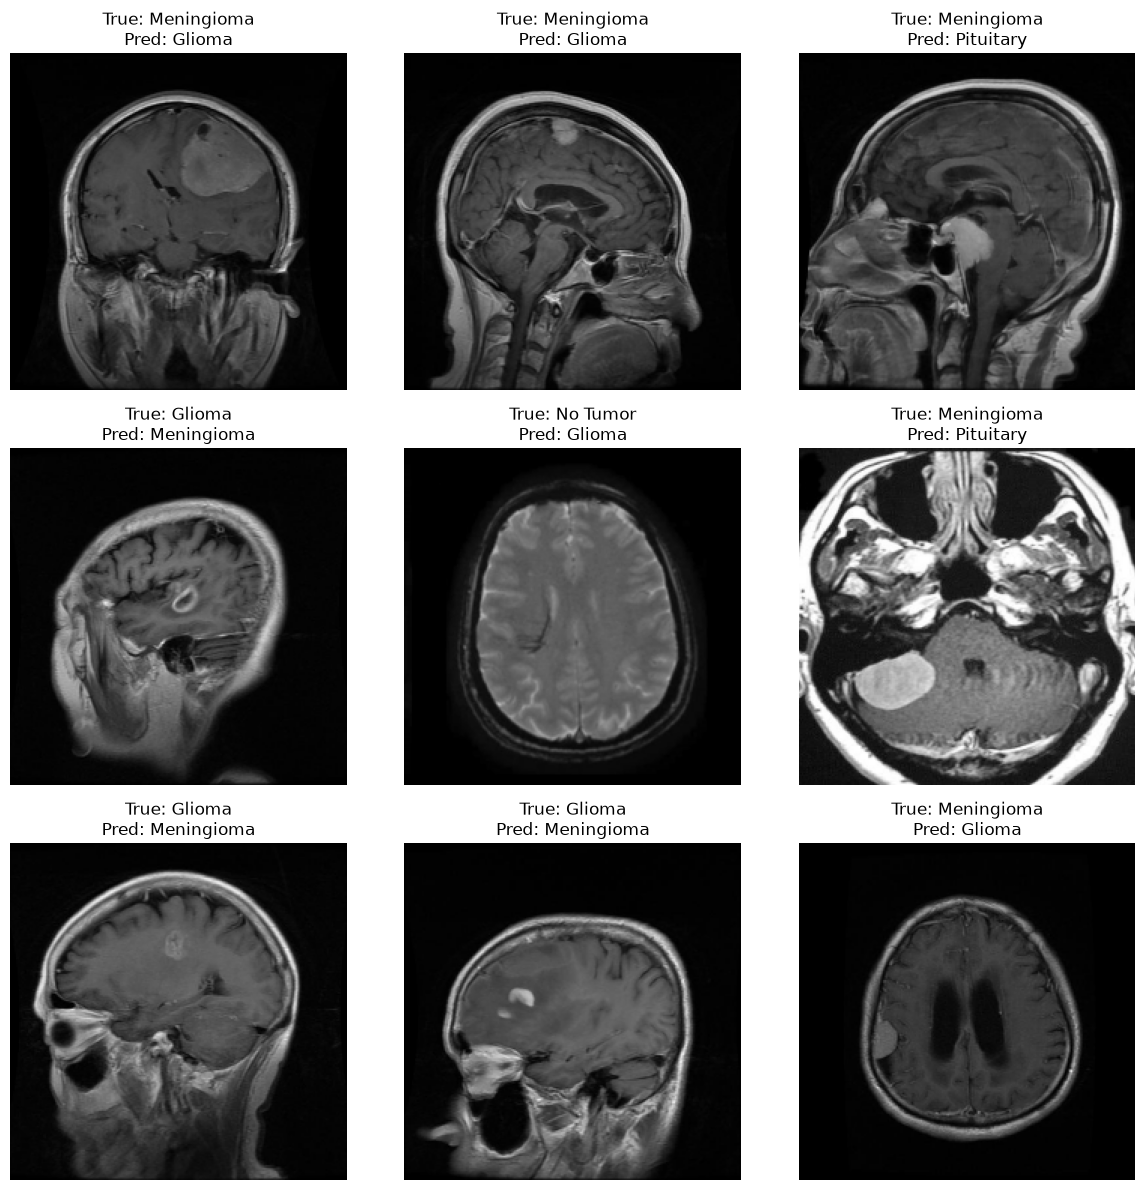

In [20]:
x_test = np.concatenate([images.numpy()for images, _ in dts_test])
class_names = ["Glioma","Meningioma","No Tumor","Pituitary"]


plt.figure(figsize=(12, 12))

for i, idx in enumerate(wrong_indices[:9]):
    plt.subplot(3, 3, i + 1)

    img = x_test[idx]

    # Reverse MobileNetV2 preprocessing for display
    img = (img + 1.0) * 127.5
    img = np.clip(img, 0, 255).astype("uint8")

    plt.imshow(img)
    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

<h1>FINE-TUNING </h1>

In [21]:
model = tf.keras.models.load_model(
    "../models/best_classification_model.keras"
)

for layer in model.layers:
    print(layer.name, type(layer).__name__)

input_layer_2 InputLayer
mobilenetv2_1.00_224 Functional
global_average_pooling2d GlobalAveragePooling2D
dense Dense
dropout Dropout
dense_1 Dense


In [22]:
model = tf.keras.models.load_model(
    "../models/best_classification_model.keras"
)

base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [23]:
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath='../models/best_fine_tuning_classification_model.keras' ,monitor="val_loss" , save_best_only=True , mode="min" , verbose=1 )
history_fine = model.fit(
    dts_train,
    validation_data=dts_val,
    epochs=15,
    callbacks=[early_s, reduce_lr, model_checkpoint]
)
joblib.dump(history_fine.history,"../models/fine_tuning_history.pkl")


Epoch 1/15


c:\Users\ouich\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.8950 - loss: 0.3208
Epoch 1: val_loss improved from None to 0.32593, saving model to ../models/best_fine_tuning_classification_model.keras

Epoch 1: finished saving model to ../models/best_fine_tuning_classification_model.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 30s 221ms/step - accuracy: 0.8950 - loss: 0.3208 - val_accuracy: 0.8867 - val_loss: 0.3259 - learning_rate: 1.0000e-04
Epoch 2/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.9612 - loss: 0.1397
Epoch 2: val_loss did not improve from 0.32593
119/119 ━━━━━━━━━━━━━━━━━━━━ 24s 199ms/step - accuracy: 0.9612 - loss: 0.1397 - val_accuracy: 0.8750 - val_loss: 0.3290 - learning_rate: 1.0000e-04
Epoch 3/15
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.9493 - loss: 0.1557
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.

Epoch 3: val_loss did not improve from 0.32593
119/119 ━━━━━━━━━━━━━━━━━━━━ 48s 256ms/step - accuracy: 0.9493 - loss: 

['../models/fine_tuning_history.pkl']

<h1>EVALUATION </h1>

In [70]:
history_fine = joblib.load("../models/fine_tuning_history.pkl")

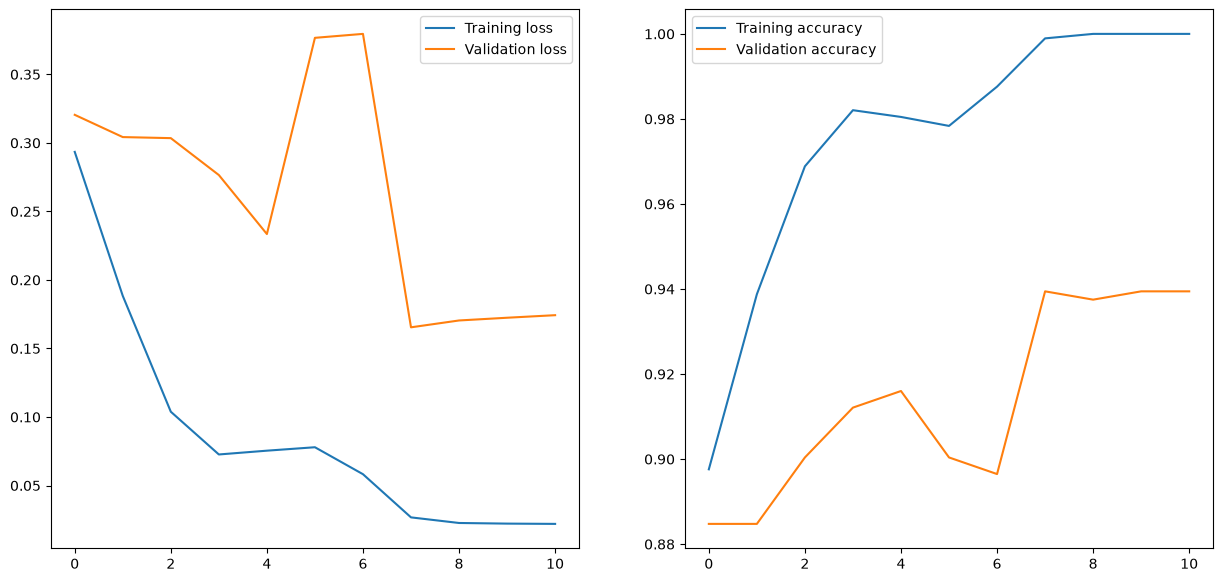

In [71]:
fig ,axes =  plt.subplots(1 , 2 , figsize=(15 , 7))
axes[0].plot(history_fine['loss'] , label="Training loss")
axes[0].plot(history_fine['val_loss'] , label="Validation loss")
axes[0].legend()

axes[1].plot(history_fine['accuracy'] , label="Training accuracy")
axes[1].plot(history_fine['val_accuracy'] , label="Validation accuracy")
axes[1].legend()
plt.show()

In [72]:
best_fine_tune = tf.keras.models.load_model('../models/best_fine_tuning_classification_model.keras')

x_test = np.concatenate([images.numpy()for images, _ in dts_test])
y_true = np.concatenate([labels.numpy() for _ , labels in dts_test])
y_pred = best_fine_tune.predict(x_test)
y_pred = np.argmax(y_pred ,axis=1)


30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 220ms/step


In [73]:
wrong_indices = np.where(y_true != y_pred)[0]
print("Incorrect predictions:", len(wrong_indices))
print("Total test images:", len(y_true))
cm = confusion_matrix(y_true=y_true , y_pred=y_pred)
report = classification_report(y_true=y_true , y_pred=y_pred , target_names=["Glioma","Meningioma","No Tumor","Pituitary"])
print('confusion_matrix : \n' , cm)
print('classification_report : \n' , report)

Incorrect predictions: 69
Total test images: 948
confusion_matrix : 
 [[201  27   0   3]
 [  5 264   3  18]
 [  2   4 132   4]
 [  0   3   0 282]]
classification_report : 
               precision    recall  f1-score   support

      Glioma       0.97      0.87      0.92       231
  Meningioma       0.89      0.91      0.90       290
    No Tumor       0.98      0.93      0.95       142
   Pituitary       0.92      0.99      0.95       285

    accuracy                           0.93       948
   macro avg       0.94      0.92      0.93       948
weighted avg       0.93      0.93      0.93       948



<h1>COMPARISON </h1>

In [77]:
fe_model = tf.keras.models.load_model('../models/best_classification_model.keras')
ft_model = tf.keras.models.load_model('../models/best_fine_tuning_classification_model.keras')

fe_test_loss , fe_test_accuracy = fe_model.evaluate(dts_test)
ft_test_loss , ft_test_accuracy = ft_model.evaluate(dts_test)

30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 175ms/step - accuracy: 0.8787 - loss: 0.3562
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 170ms/step - accuracy: 0.9272 - loss: 0.2788


In [24]:
fe_history = joblib.load("../models/best_classification_model_history.pkl")
ft_history = joblib.load("../models/fine_tuning_history.pkl")

In [78]:
print("Feature Extraction Test Loss:", fe_test_loss)
print("Feature Extraction Test Accuracy:", fe_test_accuracy)

print("FINE-TUNING Test Loss:", ft_test_loss)
print("FINE-TUNING Test Accuracy:", ft_test_accuracy)

Feature Extraction Test Loss: 0.35623934864997864
Feature Extraction Test Accuracy: 0.8786919713020325
FINE-TUNING Test Loss: 0.2787952125072479
FINE-TUNING Test Accuracy: 0.9272152185440063


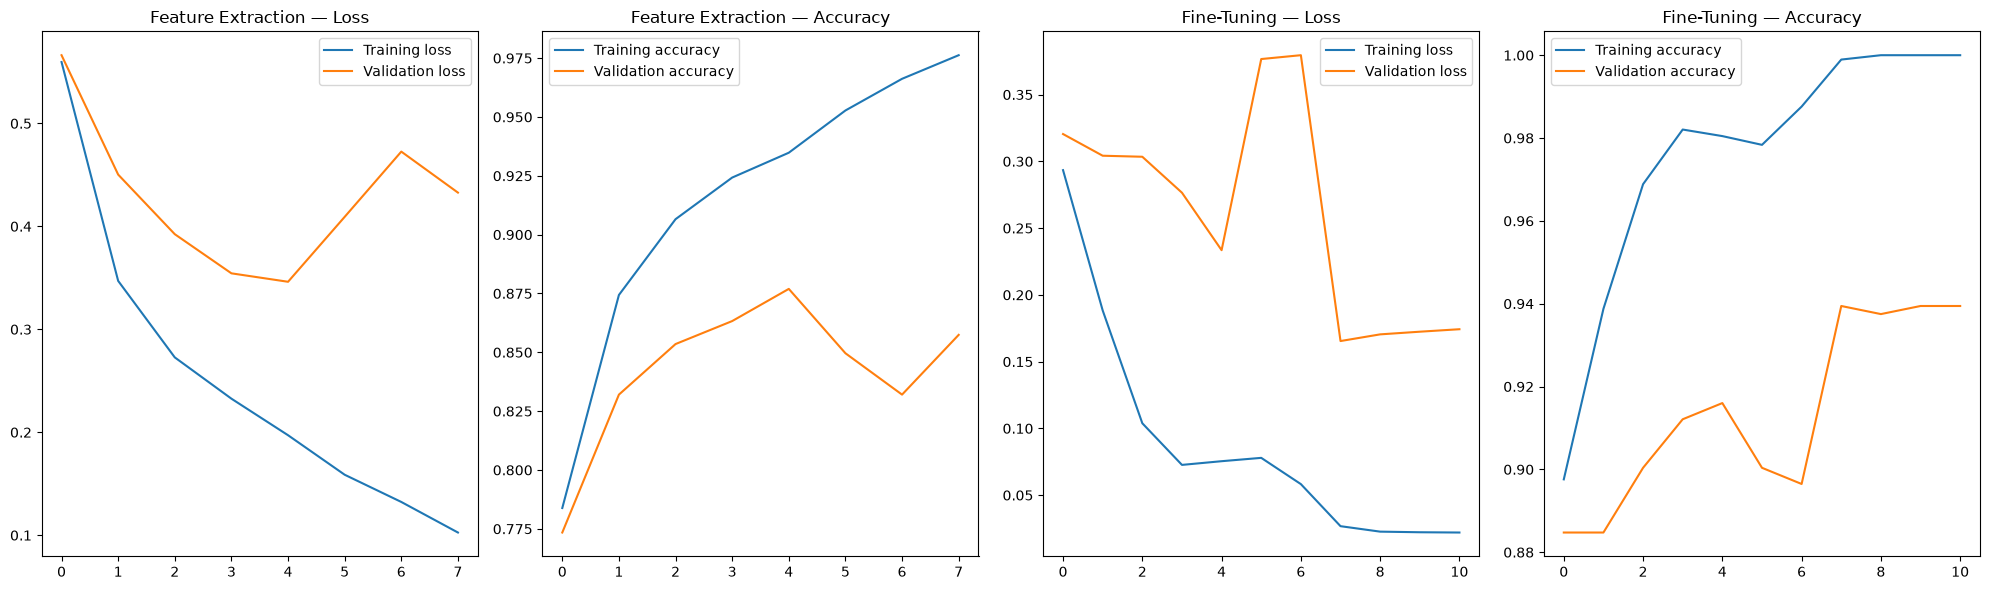

In [83]:
fe_history = joblib.load("../models/best_classification_model_history.pkl")
ft_history = joblib.load("../models/fine_tuning_history.pkl")

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# Feature Extraction — Loss
axes[0].plot(fe_history.history['loss'], label="Training loss")
axes[0].plot(fe_history.history['val_loss'], label="Validation loss")
axes[0].set_title("Feature Extraction — Loss")
axes[0].legend()

# Feature Extraction — Accuracy
axes[1].plot(fe_history.history['accuracy'], label="Training accuracy")
axes[1].plot(fe_history.history['val_accuracy'], label="Validation accuracy")
axes[1].set_title("Feature Extraction — Accuracy")
axes[1].legend()

# Fine-Tuning — Loss
axes[2].plot(ft_history['loss'], label="Training loss")
axes[2].plot(ft_history['val_loss'], label="Validation loss")
axes[2].set_title("Fine-Tuning — Loss")
axes[2].legend()

# Fine-Tuning — Accuracy
axes[3].plot(ft_history['accuracy'], label="Training accuracy")
axes[3].plot(ft_history['val_accuracy'], label="Validation accuracy")
axes[3].set_title("Fine-Tuning — Accuracy")
axes[3].legend()

plt.tight_layout()
plt.show()

In [84]:
# Best validation accuracy and corresponding training accuracy
for name, hist in [
    ("Feature Extraction", fe_history.history),
    ("Fine-Tuning", ft_history)
]:
    best_epoch = np.argmax(hist["val_accuracy"])

    train_acc = hist["accuracy"][best_epoch]
    val_acc = hist["val_accuracy"][best_epoch]

    print(name)
    print("Best epoch:", best_epoch + 1)
    print("Training accuracy:", round(train_acc, 4))
    print("Validation accuracy:", round(val_acc, 4))
    print("Accuracy gap:", round(train_acc - val_acc, 4))

Feature Extraction
Best epoch: 5
Training accuracy: 0.9348
Validation accuracy: 0.877
Accuracy gap: 0.0579
Fine-Tuning
Best epoch: 8
Training accuracy: 0.9989
Validation accuracy: 0.9395
Accuracy gap: 0.0595
